# Генеративные текстовые модели: токенизация по словам

**Участник 1.** Отвечает за полный спектр моделей с **пословной токенизацией**
(участники 2 и 3 обучают те же архитектуры с посимвольной токенизацией и BPE).

**Датасет:** англоязычная литература с Project Gutenberg — все 9 книг о Шерлоке Холмсе
(А. Конан Дойл: 4 романа и 5 сборников рассказов, около 3,5 млн символов).

**Архитектуры:**
1. Simple RNN;
2. однонаправленная LSTM — однослойная и двухслойная;
3. двунаправленная LSTM (BiLSTM);
4. трансформер-декодер GPT, написанный «с нуля».

**План:** данные → пословная токенизация и статистика словаря → модели → обучение →
сравнение метрик → генерация текста → почему BiLSTM нельзя обучать «в лоб» → выводы.

In [1]:
import math
import os
import random
import re
import time
import urllib.request
from collections import Counter
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torch.nn.functional as F
from IPython.display import display

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

device = "cuda" if torch.cuda.is_available() else "cpu"
torch.backends.cuda.matmul.allow_tf32 = True
torch.backends.cudnn.allow_tf32 = True

DATA_DIR, IMG_DIR, CKPT_DIR, RESULTS_DIR = Path("data"), Path("images"), Path("checkpoints"), Path("results")
for d in (DATA_DIR, IMG_DIR, CKPT_DIR, RESULTS_DIR):
    d.mkdir(exist_ok=True)

plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3})
print(f"PyTorch {torch.__version__}, устройство: {device}"
      + (f" ({torch.cuda.get_device_name(0)})" if device == "cuda" else ""))

PyTorch 2.11.0+cu128, устройство: cuda (NVIDIA GeForce RTX 3060)


## 1. Данные

Скачиваем книги с gutenberg.org (они кэшируются в `data/raw/`) и чистим:
- отрезаем служебный заголовок и лицензию Project Gutenberg, а в «The Case-Book» — рекламу издательства;
- склеиваем строки внутри абзаца: в исходниках текст разбит переносами по ~70 символов;
- убираем оглавления, заголовки глав, подписи к иллюстрациям и сноски;
- приводим типографику к одному виду. В «The Case-Book» прямые кавычки `"` и двойной дефис `--`,
  в остальных книгах «фигурные» кавычки `“ ”` и тире `—`. Без этого одни и те же знаки
  превратились бы в разные токены;
- убираем `_подчёркивания_`, которыми в Gutenberg размечен курсив.

Разбиение на train/val/test делаем **внутри каждой книги**: первые 90 % текста → train,
следующие 5 % → val, последние 5 % → test. Так тест покрывает все книги, а куски одного абзаца
не попадают одновременно в обучение и в тест. Файлы `data/train.txt`, `data/val.txt`, `data/test.txt`
общие для всей команды: на одном и том же тесте можно сравнивать разные токенизации.

In [2]:
BOOKS = {  # номер книги на gutenberg.org: название
    244: "A Study in Scarlet",
    2097: "The Sign of the Four",
    1661: "The Adventures of Sherlock Holmes",
    834: "The Memoirs of Sherlock Holmes",
    2852: "The Hound of the Baskervilles",
    108: "The Return of Sherlock Holmes",
    3289: "The Valley of Fear",
    2350: "His Last Bow",
    69700: "The Case-Book of Sherlock Holmes",
}


def download_book(book_id):
    path = DATA_DIR / "raw" / f"pg{book_id}.txt"
    if not path.exists():
        path.parent.mkdir(parents=True, exist_ok=True)
        url = f"https://www.gutenberg.org/cache/epub/{book_id}/pg{book_id}.txt"
        request = urllib.request.Request(url, headers={"User-Agent": "Mozilla/5.0 (student lab)"})
        path.write_bytes(urllib.request.urlopen(request, timeout=60).read())
    return path.read_text(encoding="utf-8-sig")


def smart_quotes(text):
    """Прямые кавычки → «фигурные»: открывающая — после начала строки, пробела, скобки или тире."""
    text = re.sub(r'(^|[\s(\[—‘“])"', r"\1“", text, flags=re.M)
    text = text.replace('"', "”")
    text = re.sub(r"(^|[\s(\[—“])'", r"\1‘", text, flags=re.M)
    return text.replace("'", "’")


def is_heading(p):
    """Заголовки, титулы и оглавления — не связный текст."""
    letters = [c for c in p if c.isalpha()]
    if not letters or "|" in p or "+--" in p:                    # нет букв или ASCII-рамка
        return True
    if sum(c.isupper() for c in letters) / len(letters) > 0.8:   # капсом: «CHAPTER I.», «PREFACE»
        return True
    if not re.search(r"[.!?;:”’—)]$", p):                        # нет конечной пунктуации:
        return len(p) < 150 or len(re.findall(r"\b(?:Chapter|Adventure|[IVX]+\.)", p)) >= 3
    return False


def clean_book(raw):
    start = raw.find("\n", raw.find("*** START OF")) + 1
    text = raw[start:raw.find("*** END OF")]
    text = text.split("Printed in Great Britain")[0]         # реклама издательства в конце «The Case-Book»
    text = re.sub(r"\[Illustration[^\]]*\]", "", text)        # подписи к иллюстрациям
    if '"' in text:
        text = smart_quotes(text)
    text = text.replace("--", "—").replace("_", "").replace("・", "")
    paragraphs = []
    for block in re.split(r"\n\s*\n", text):
        p = " ".join(block.split())                           # склеиваем строки абзаца
        if p and not re.match(r"\[\d+\]", p) and not is_heading(p):   # «[1] ...» — текст сноски
            paragraphs.append(re.sub(r"\[\d+\]", "", p))         # «[1]» — ссылка на сноску
    return paragraphs


def split_book(paragraphs, val_frac=0.05, test_frac=0.05):
    """Первые 90 % символов книги → train, следующие 5 % → val, последние 5 % → test."""
    ends = np.cumsum([len(p) + 1 for p in paragraphs])
    i_val = int(np.searchsorted(ends, ends[-1] * (1 - val_frac - test_frac)))
    i_test = int(np.searchsorted(ends, ends[-1] * (1 - test_frac)))
    return paragraphs[:i_val], paragraphs[i_val:i_test], paragraphs[i_test:]


splits = {"train": [], "val": [], "test": []}
book_stats = []
for book_id, title in BOOKS.items():
    paragraphs = clean_book(download_book(book_id))
    for name, part in zip(splits, split_book(paragraphs)):
        splits[name] += part
    book_stats.append({"Книга": title, "Абзацев": len(paragraphs),
                       "Символов": sum(map(len, paragraphs)),
                       "Слов": sum(len(p.split()) for p in paragraphs)})

texts = {}
for name, paragraphs in splits.items():
    texts[name] = "\n".join(paragraphs) + "\n"
    (DATA_DIR / f"{name}.txt").write_text(texts[name], encoding="utf-8")

book_stats = pd.DataFrame(book_stats)
book_stats.loc[len(book_stats)] = ["Всего", *book_stats.iloc[:, 1:].sum()]
display(book_stats)
print({name: f"{len(t):,} символов" for name, t in texts.items()})
print("\nПример абзаца:\n", splits["train"][100])

,Книга,Абзацев,Символов,Слов
0,A Study in Scarlet,791,236237,43187
1,The Sign of the Four,773,229363,42919
2,The Adventures of Sherlock Holmes,2518,555475,104322
3,The Memoirs of Sherlock Holmes,2178,509539,95349
4,The Hound of the Baskervilles,1470,314110,59040
5,The Return of Sherlock Holmes,2542,602140,111904
6,The Valley of Fear,1504,308454,57497
7,His Last Bow,1416,319994,58884
8,The Case-Book of Sherlock Holmes,2219,441161,82340
9,Всего,15411,3516473,655442


{'train': '3,174,766 символов', 'val': '178,290 символов', 'test': '178,828 символов'}

Пример абзаца:
 “But do you mean to say,” I said, “that without leaving your room you can unravel some knot which other men can make nothing of, although they have seen every detail for themselves?”


## 2. Токенизация по словам

Правила разбиения (регулярное выражение `TOKEN_RE`):
- **слово** — последовательность букв; апостроф внутри слова сохраняется (`o’clock`);
- **клитики** отделяются: `Holmes’s` → `Holmes` + `’s`, `don’t` → `don` + `’t`, `I’ll` → `I` + `’ll`.
  Иначе каждая притяжательная форма была бы отдельным, обычно редким, словом;
- **дефис** — отдельный токен: `to-morrow` → `to` `-` `morrow`. Составные слова почти все редкие,
  а их части модель знает;
- **числа** и **знаки препинания** (`. , ; ! ? “ ” ‘ ’ — -`) — отдельные токены;
- **конец абзаца** — служебный токен `<p>`;
- **регистр сохраняем**: `The` и `the` — разные токены. Генерация сразу выглядит как обычный текст,
  а токенизация остаётся почти обратимой: это нужно, чтобы честно сравнить модели с посимвольными.

Словарь строим **только по train**. Слова, которые встретились реже `MIN_FREQ` раз, заменяются на `<unk>`.
Обратное преобразование (детокенизация) расставляет пробелы по правилам: нет пробела перед
`. , ; : ! ? ” ’` и клитиками, нет пробела после `“ ‘ (`; дефис и тире приклеиваются с обеих сторон.

In [3]:
class WordTokenizer:
    """Пословный токенизатор: слова, клитики, числа и знаки препинания — отдельные токены, абзац — <p>."""

    TOKEN_RE = re.compile(r"""
          [^\W\d_]+(?:’(?!(?i:s|t|d|m|ll|re|ve)\b)[^\W\d_]+)*   # слово (апостроф внутри: o’clock)
        | ’(?i:s|t|d|m|ll|re|ve)\b                            # клитики: ’s ’t ’d ’m ’ll ’re ’ve
        | \d+(?:[.,]\d+)*                                      # числа: 1888, 4.30
        | \n                                                   # конец абзаца
        | \S                                                   # остальное: . , ; ! ? “ ” — - £ ...
    """, re.VERBOSE)
    UNK, PAR = "<unk>", "<p>"
    ATTACH_LEFT = set(".,;:!?)]”’-—½")   # перед этими символами (и клитиками ’s, ’t, ...) пробела нет
    ATTACH_RIGHT = set("([“‘-—£")        # после этих символов пробела нет

    def tokenize(self, text):
        return [self.PAR if t == "\n" else t for t in self.TOKEN_RE.findall(text)]

    def detokenize(self, tokens):
        out, glue = [], True                 # glue: следующий токен приклеить без пробела
        for t in tokens:
            if t == self.PAR:
                out.append("\n")
                glue = True
                continue
            if not (glue or t[0] in self.ATTACH_LEFT):
                out.append(" ")
            out.append(t)
            glue = t in self.ATTACH_RIGHT
        return "".join(out)

    def fit(self, tokens, min_freq):
        self.counts = Counter(tokens)
        words = [w for w, c in self.counts.most_common() if c >= min_freq and w != self.PAR]
        self.itos = [self.UNK, self.PAR] + words
        self.stoi = {w: i for i, w in enumerate(self.itos)}
        return self

    def __len__(self):
        return len(self.itos)

    def encode(self, tokens):
        return [self.stoi.get(t, 0) for t in tokens]   # 0 — индекс <unk>

    def decode(self, ids):
        return self.detokenize(self.itos[i] for i in ids)


tok = WordTokenizer()
example = "“Holmes’s cab-horse won’t wait,” said I. It was to-morrow, at 4.30 o’clock—£500 lost."
print(tok.tokenize(example))
print(tok.detokenize(tok.tokenize(example)))

['“', 'Holmes', '’s', 'cab', '-', 'horse', 'won', '’t', 'wait', ',', '”', 'said', 'I', '.', 'It', 'was', 'to', '-', 'morrow', ',', 'at', '4.30', 'o’clock', '—', '£', '500', 'lost', '.']
“Holmes’s cab-horse won’t wait,” said I. It was to-morrow, at 4.30 o’clock—£500 lost.


In [4]:
tokens = {name: tok.tokenize(t) for name, t in texts.items()}
counts = Counter(tokens["train"])
print({name: f"{len(t):,} токенов" for name, t in tokens.items()},
      f"\nуникальных токенов в train: {len(counts):,}")

rows = []
for min_freq in [1, 2, 3, 5, 10]:
    vocab = {w for w, c in counts.items() if c >= min_freq}
    oov = {name: 100 * np.mean([t not in vocab for t in tokens[name]]) for name in ("train", "val", "test")}
    rows.append({"MIN_FREQ": min_freq, "Размер словаря": len(vocab) + 1,
                 "<unk> в train, %": oov["train"], "<unk> в val, %": oov["val"], "<unk> в test, %": oov["test"]})
display(pd.DataFrame(rows).round(2))

paragraphs = [p for p in texts["val"].split("\n") if p]
restored = np.mean([tok.detokenize(tok.tokenize(p)) == p for p in paragraphs])
print(f"Детокенизация восстанавливает {100 * restored:.1f} % абзацев val один в один")

{'train': '734,444 токенов', 'val': '41,125 токенов', 'test': '40,972 токенов'}

 
уникальных токенов в train: 19,997


,MIN_FREQ,Размер словаря,"<unk> в train, %","<unk> в val, %","<unk> в test, %"
0,1,19998,0.00,1.37,1.67
1,2,12611,1.01,2.20,2.46
2,3,9689,1.80,2.94,3.19
3,5,6822,3.13,4.18,4.26
4,10,4242,5.44,6.45,6.27


Детокенизация восстанавливает 98.4 % абзацев val один в один


Берём `MIN_FREQ = 3`: словарь около 9,7 тыс. слов (как в классическом бенчмарке Penn Treebank — 10 тыс.),
а `<unk>` занимает около 3 % токенов теста. При `MIN_FREQ = 1` словарь вдвое больше, но больше трети
его слов (7,4 тыс.) встречается в train ровно один раз — осмысленный эмбеддинг по одному примеру не выучить.

Частоты слов подчиняются **закону Ципфа**: частота примерно обратно пропорциональна рангу слова.
50 самых частых токенов покрывают больше половины текста, 1000 — 85 %, а «хвост» редких слов огромен:
словарь любого разумного размера не покрывает текст полностью. В этом главная слабость пословной токенизации.

Размер словаря V = 9,689; доля <unk>: train 1.80 %, val 2.94 %, test 3.19 %


30 самых частых токенов: [',', '.', 'the', 'I', 'and', 'of', '“', 'to', 'a', '”', 'that', 'in', 'was', 'it', 'you', 'he', 'his', 'is', 'had', 'have', 'with', '?', 'my', 'for', 'as', 'at', 'which', '-', 'me', 'not']

Пример → индексы: [8, 36, 37, 454, 29, 590, 548, 95, 736, 2, 11, 35, 5, 3, 41, 14, 9, 29, 694, 2, 27, 0, 475, 56, 1668, 0, 478, 3]
и обратно: “Holmes’s cab-horse won’t wait,” said I. It was to-morrow, at <unk> o’clock—£<unk> lost.


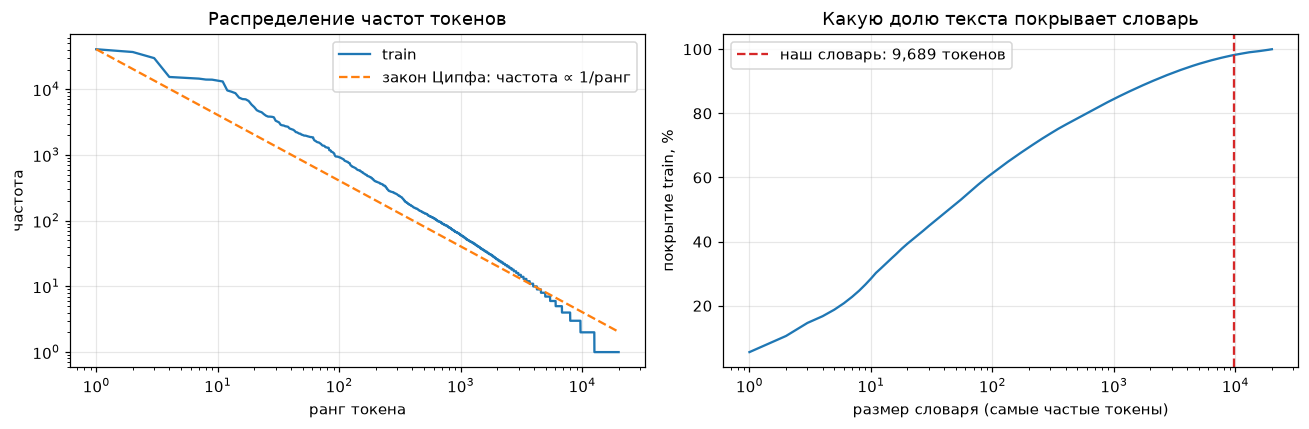

In [5]:
MIN_FREQ = 3
tok.fit(tokens["train"], MIN_FREQ)
V = len(tok)
ids = {name: torch.tensor(tok.encode(t), dtype=torch.long, device=device) for name, t in tokens.items()}
print(f"Размер словаря V = {V:,}; доля <unk>: "
      + ", ".join(f"{name} {100 * (x == 0).float().mean().item():.2f} %" for name, x in ids.items()))
print("30 самых частых токенов:", tok.itos[2:32])
example_ids = tok.encode(tok.tokenize(example))
print("\nПример → индексы:", example_ids)
print("и обратно:", tok.decode(example_ids))

freqs = np.array(sorted(counts.values(), reverse=True))
ranks = np.arange(1, len(freqs) + 1)
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].loglog(ranks, freqs, label="train")
axes[0].loglog(ranks, freqs[0] / ranks, "--", label="закон Ципфа: частота ∝ 1/ранг")
axes[0].set(xlabel="ранг токена", ylabel="частота", title="Распределение частот токенов")
axes[0].legend()
axes[1].semilogx(ranks, 100 * np.cumsum(freqs) / freqs.sum())
axes[1].axvline(V, color="C3", ls="--", label=f"наш словарь: {V:,} токенов")
axes[1].set(xlabel="размер словаря (самые частые токены)", ylabel="покрытие train, %",
            title="Какую долю текста покрывает словарь")
axes[1].legend()
plt.tight_layout()
plt.savefig(IMG_DIR / "zipf.png", bbox_inches="tight")
plt.show()

## 3. Модели

У всех моделей одинаковые вход и выход:
- **эмбеддинги** слов размерности 256;
- **выходной слой связан с эмбеддингами** (weight tying): одна и та же матрица `V × 256` превращает слово
  в вектор и вектор — в логиты всех слов. Это убирает 2,5 млн параметров и на небольших данных
  улучшает перплексию. Поэтому скрытое состояние рекуррентных сетей (512) сначала проецируется в 256;
- **dropout** на эмбеддингах и перед выходным слоем — главная защита от переобучения:
  в train всего 0,73 млн токенов.

| Модель | Что внутри |
|---|---|
| Simple RNN | один слой `h_t = tanh(W·x_t + U·h_{t-1} + b)`, скрытое состояние 512 |
| LSTM, 1 слой | ячейка LSTM (входной, забывающий и выходной вентили), скрытое состояние 512 |
| LSTM, 2 слоя | две LSTM друг над другом, dropout между слоями |
| BiLSTM | LSTM, которая читает окно контекста слева направо и справа налево: 256 в каждую сторону, в сумме 512 — как у однослойной LSTM |
| GPT | 4 блока трансформера-декодера: маскированное многоголовое самовнимание (4 головы) + MLP, pre-LayerNorm, обучаемые позиционные эмбеддинги |

**Как генерировать двунаправленной LSTM.** На позиции *t* двунаправленная сеть видит слова и слева,
и справа. Если учить её как обычную языковую модель, то есть предсказывать слово *t+1* на каждой позиции,
обратный проход уже прочитал правильный ответ, и сеть просто его копирует (в разделе 7 это проверено).
Поэтому BiLSTM работает по схеме **many-to-one**: на вход подаётся окно из *L* предыдущих слов (только прошлое),
сеть читает его в обе стороны, и по склеенным финальным состояниям прямого и обратного проходов
предсказывается **одно** следующее слово. Длину окна *L* в каждом батче выбираем случайно от 1 до 64,
чтобы модель умела продолжать и короткую затравку: однонаправленные модели видят контексты всех длин
автоматически.

In [6]:
EMB_DIM, HIDDEN = 256, 512


class RNNLM(nn.Module):
    """Simple RNN или LSTM: на каждой позиции предсказывает следующее слово (many-to-many)."""

    kind = "m2m"

    def __init__(self, vocab_size, cell="lstm", hidden=HIDDEN, layers=1, dropout=0.3, bidirectional=False):
        super().__init__()
        self.emb = nn.Embedding(vocab_size, EMB_DIM)
        rnn_class = nn.LSTM if cell == "lstm" else nn.RNN
        self.rnn = rnn_class(EMB_DIM, hidden, num_layers=layers, batch_first=True,
                             dropout=dropout if layers > 1 else 0.0, bidirectional=bidirectional)
        self.drop = nn.Dropout(dropout)
        self.proj = nn.Linear(hidden * (2 if bidirectional else 1), EMB_DIM)
        self.head = nn.Linear(EMB_DIM, vocab_size)
        self.head.weight = self.emb.weight              # weight tying
        nn.init.uniform_(self.emb.weight, -0.1, 0.1)
        nn.init.zeros_(self.head.bias)

    def features(self, x):                              # (B, T) → (B, T, EMB_DIM)
        h, _ = self.rnn(self.drop(self.emb(x)))
        return self.proj(self.drop(h))

    def forward(self, x):                               # логиты на каждой позиции: (B, T, V)
        return self.head(self.features(x))

    def next_logits(self, ctx):                         # логиты слова после контекста: (B, V)
        return self.head(self.features(ctx)[:, -1])


class BiLSTMLM(nn.Module):
    """BiLSTM: читает окно предыдущих слов в обе стороны и предсказывает одно следующее слово (many-to-one)."""

    kind = "m2o"

    def __init__(self, vocab_size, hidden=HIDDEN, layers=1, dropout=0.3):
        super().__init__()
        self.emb = nn.Embedding(vocab_size, EMB_DIM)
        self.rnn = nn.LSTM(EMB_DIM, hidden, num_layers=layers, batch_first=True, bidirectional=True,
                           dropout=dropout if layers > 1 else 0.0)
        self.drop = nn.Dropout(dropout)
        self.proj = nn.Linear(2 * hidden, EMB_DIM)
        self.head = nn.Linear(EMB_DIM, vocab_size)
        self.head.weight = self.emb.weight
        nn.init.uniform_(self.emb.weight, -0.1, 0.1)
        nn.init.zeros_(self.head.bias)

    def forward(self, ctx):                             # (B, L) → логиты следующего слова (B, V)
        _, (h_n, _) = self.rnn(self.drop(self.emb(ctx)))
        # h_n[-2] — прямой проход верхнего слоя (закончил чтение на последнем слове окна),
        # h_n[-1] — обратный проход (закончил на первом слове окна)
        h = torch.cat([h_n[-2], h_n[-1]], dim=-1)
        return self.head(self.proj(self.drop(h)))

    def next_logits(self, ctx):
        return self(ctx)

### GPT «с нуля»

Каждая голова самовнимания считает `Attention(Q, K, V) = softmax(Q·Kᵀ / √d + M) · V`, где `Q, K, V` —
линейные проекции входа, `d` — размерность головы, а маска `M` равна −∞ над диагональю: позиция *t* не видит
слова после себя, иначе модель подглядывала бы в ответ. Выходы 4 голов склеиваются и проецируются обратно.
Блок: `x + Attention(LayerNorm(x))`, затем `x + MLP(LayerNorm(x))` (pre-LN, как в GPT-2). Порядок слов
модель узнаёт только из позиционных эмбеддингов, которые прибавляются к эмбеддингам слов.

In [7]:
class CausalSelfAttention(nn.Module):
    """Многоголовое самовнимание с маской: позиция t видит только позиции 0..t."""

    def __init__(self, d_model, n_heads, block_size, dropout):
        super().__init__()
        self.n_heads = n_heads
        self.qkv = nn.Linear(d_model, 3 * d_model)      # Q, K, V для всех голов одним умножением
        self.out = nn.Linear(d_model, d_model)
        self.attn_drop, self.resid_drop = nn.Dropout(dropout), nn.Dropout(dropout)
        self.register_buffer("mask", torch.tril(torch.ones(block_size, block_size, dtype=torch.bool)),
                             persistent=False)

    def forward(self, x):
        B, T, C = x.shape
        q, k, v = self.qkv(x).split(C, dim=2)
        # (B, T, C) → (B, головы, T, C / головы)
        q, k, v = (t.view(B, T, self.n_heads, C // self.n_heads).transpose(1, 2) for t in (q, k, v))
        att = q @ k.transpose(-2, -1) / math.sqrt(k.size(-1))       # (B, головы, T, T)
        att = att.masked_fill(~self.mask[:T, :T], float("-inf"))    # будущее не видно
        att = F.softmax(att, dim=-1)
        self.last_attention = att.detach()                          # для визуализации в разделе 6
        att = self.attn_drop(att)
        y = (att @ v).transpose(1, 2).reshape(B, T, C)              # склеиваем головы обратно
        return self.resid_drop(self.out(y))


class Block(nn.Module):
    """Блок трансформера-декодера: x + Attention(LN(x)), затем x + MLP(LN(x))."""

    def __init__(self, d_model, n_heads, block_size, dropout):
        super().__init__()
        self.ln1, self.ln2 = nn.LayerNorm(d_model), nn.LayerNorm(d_model)
        self.attn = CausalSelfAttention(d_model, n_heads, block_size, dropout)
        self.mlp = nn.Sequential(nn.Linear(d_model, 4 * d_model), nn.GELU(),
                                 nn.Linear(4 * d_model, d_model), nn.Dropout(dropout))

    def forward(self, x):
        x = x + self.attn(self.ln1(x))
        return x + self.mlp(self.ln2(x))


class GPT(nn.Module):
    """Трансформер-декодер в духе GPT-2 / nanoGPT."""

    kind = "m2m"

    def __init__(self, vocab_size, block_size, n_layers=4, n_heads=4, dropout=0.2):
        super().__init__()
        self.block_size = block_size
        self.tok_emb = nn.Embedding(vocab_size, EMB_DIM)
        self.pos_emb = nn.Embedding(block_size, EMB_DIM)   # обучаемые позиционные эмбеддинги
        self.drop = nn.Dropout(dropout)
        self.blocks = nn.ModuleList(Block(EMB_DIM, n_heads, block_size, dropout) for _ in range(n_layers))
        self.ln_f = nn.LayerNorm(EMB_DIM)
        self.head = nn.Linear(EMB_DIM, vocab_size, bias=False)
        self.head.weight = self.tok_emb.weight             # weight tying
        self.apply(self._init_weights)
        for name, p in self.named_parameters():            # как в GPT-2: уменьшаем веса на выходе
            if name.endswith(("attn.out.weight", "mlp.2.weight")):   # residual-веток
                nn.init.normal_(p, std=0.02 / math.sqrt(2 * n_layers))

    @staticmethod
    def _init_weights(m):
        if isinstance(m, (nn.Linear, nn.Embedding)):
            nn.init.normal_(m.weight, std=0.02)
        if isinstance(m, nn.Linear) and m.bias is not None:
            nn.init.zeros_(m.bias)

    def features(self, x):
        pos = torch.arange(x.size(1), device=x.device)
        h = self.drop(self.tok_emb(x) + self.pos_emb(pos))
        for block in self.blocks:
            h = block(h)
        return self.ln_f(h)

    def forward(self, x):
        return self.head(self.features(x))

    def next_logits(self, ctx):
        return self.head(self.features(ctx[:, -self.block_size:])[:, -1])

## 4. Обучение

Условия одинаковые для всех моделей:
- **контекст 64 слова**. GPT больше и не видит (`block_size = 64`), рекуррентные сети учим на окнах той же длины;
- **4096 целевых слов на шаг оптимизатора**: 64 окна × 64 позиции у однонаправленных моделей и 4096 окон
  по одному целевому слову у BiLSTM. Эпоха — один проход по всем словам train, около 180 шагов;
- **AdamW** с линейным разогревом learning rate (200 шагов) и обрезкой нормы градиента до 1
  (без неё Simple RNN «взрывается»);
- **уменьшение lr и ранняя остановка**: если после эпохи loss на val не улучшился, lr уменьшается вдвое;
  если не улучшается 3 эпохи подряд — обучение останавливается и возвращаются веса лучшей эпохи
  (максимум 40 эпох);
- **одинаковая оценка**: loss на val/test считается так, что у **каждого** слова контекст — ровно 64 предыдущих
  слова (окно скользит по тексту с шагом 1). Ни одна архитектура не получает больше или меньше контекста,
  поэтому метрики сравнимы. Train loss на графиках посчитан так же (на фиксированных 20 тыс. позиций train)
  и без dropout, поэтому разрыв между train и val — это именно переобучение.

In [8]:
SEQ_LEN = 64             # контекст: 64 слова
TARGETS_PER_STEP = 4096  # целевых слов на один шаг оптимизатора
MICRO_BATCH = 2048       # окон за один проход: 4096 окон BiLSTM разом не помещаются в память GPU
MAX_EPOCHS = int(os.environ.get("MAX_EPOCHS", 40))
PATIENCE = 3


def batches(data, kind):
    """Одна эпоха: каждое слово train ровно один раз становится целевым."""
    n = len(data)
    if kind == "m2m":    # окна по SEQ_LEN слов со случайным сдвигом начала
        starts = torch.arange(random.randrange(SEQ_LEN), n - SEQ_LEN - 1, SEQ_LEN, device=data.device)
        starts = starts[torch.randperm(len(starts), device=data.device)]
        per_batch = TARGETS_PER_STEP // SEQ_LEN
        for i in range(0, len(starts), per_batch):
            chunk = data[starts[i:i + per_batch, None] + torch.arange(SEQ_LEN + 1, device=data.device)]
            yield chunk[:, :-1], chunk[:, 1:]
    else:                # many-to-one: окно из L предыдущих слов → следующее слово
        targets = SEQ_LEN + torch.randperm(n - SEQ_LEN, device=data.device)
        for i in range(0, len(targets), TARGETS_PER_STEP):
            tgt = targets[i:i + TARGETS_PER_STEP]
            L = random.randint(1, SEQ_LEN)
            yield data[tgt[:, None] - L + torch.arange(L, device=data.device)], data[tgt]


@torch.no_grad()
def evaluate(model, data, max_targets=None, batch_size=1024):
    """Средняя кросс-энтропия (нат/слово); у каждого слова контекст — ровно SEQ_LEN предыдущих слов."""
    model.eval()
    targets = torch.arange(SEQ_LEN, len(data), device=data.device)
    if max_targets is not None and len(targets) > max_targets:   # фиксированная подвыборка позиций
        g = torch.Generator().manual_seed(0)
        targets = targets[torch.randperm(len(targets), generator=g)[:max_targets].to(data.device)]
    total = 0.0
    for i in range(0, len(targets), batch_size):
        tgt = targets[i:i + batch_size]
        ctx = data[tgt[:, None] - SEQ_LEN + torch.arange(SEQ_LEN, device=data.device)]
        total += F.cross_entropy(model.next_logits(ctx), data[tgt], reduction="sum").item()
    return total / len(targets)

In [9]:
def train_model(model, lr, weight_decay=0.01, warmup=200, max_epochs=MAX_EPOCHS, patience=PATIENCE):
    params = list(model.parameters())
    groups = [{"params": [p for p in params if p.dim() >= 2], "weight_decay": weight_decay},
              {"params": [p for p in params if p.dim() < 2], "weight_decay": 0.0}]  # bias и LayerNorm не штрафуем
    opt = torch.optim.AdamW(groups, lr=lr, betas=(0.9, 0.98))

    history, best_loss, best_state, bad_epochs, train_time = [], float("inf"), None, 0, 0.0
    step, lr_scale = 0, 1.0
    for epoch in range(1, max_epochs + 1):
        model.train()
        t0 = time.perf_counter()
        for x, y in batches(ids["train"], model.kind):
            for group in opt.param_groups:                  # линейный разогрев, затем lr * lr_scale
                group["lr"] = lr * lr_scale * min(1.0, (step + 1) / warmup)
            step += 1
            opt.zero_grad(set_to_none=True)
            for xb, yb in zip(x.split(MICRO_BATCH), y.split(MICRO_BATCH)):   # накопление градиента
                logits = model(xb)
                loss = F.cross_entropy(logits.reshape(-1, logits.size(-1)), yb.reshape(-1),
                                       reduction="sum") / y.numel()
                loss.backward()
            nn.utils.clip_grad_norm_(params, 1.0)
            opt.step()
        if device == "cuda":
            torch.cuda.synchronize()
        train_time += time.perf_counter() - t0

        train_loss = evaluate(model, ids["train"], max_targets=20_000)
        val_loss = evaluate(model, ids["val"])
        history.append({"epoch": epoch, "train_loss": train_loss, "val_loss": val_loss, "time": train_time})
        print(f"эпоха {epoch:2d} | lr {lr * lr_scale:.1e} | train loss {train_loss:.3f} | val loss {val_loss:.3f} "
              f"| val PPL {math.exp(val_loss):6.1f} | {train_time:4.0f} с")
        if val_loss < best_loss:
            best_loss, bad_epochs = val_loss, 0
            best_state = {k: v.detach().clone() for k, v in model.state_dict().items()}
        else:
            bad_epochs += 1
            lr_scale /= 2                                   # val не улучшился — уменьшаем lr вдвое
            if bad_epochs >= patience:
                print(f"ранняя остановка: лучшая эпоха {epoch - patience}")
                break
    model.load_state_dict(best_state)
    return history, train_time


RETRAIN = False   # True — обучать заново, даже если веса уже сохранены в checkpoints/


def fit_or_load(key, cfg):
    torch.manual_seed(SEED)
    random.seed(SEED)
    model = cfg["make"](cfg["dropout"]).to(device)
    path = CKPT_DIR / f"{key}.pt"
    if path.exists() and not RETRAIN:
        ckpt = torch.load(path, map_location=device)
        model.load_state_dict(ckpt["state"])
        history, train_time = ckpt["history"], ckpt["train_time"]
        print(f"{cfg['name']}: веса загружены из {path}")
    else:
        history, train_time = train_model(model, cfg["lr"], cfg.get("weight_decay", 0.01))
        torch.save({"state": model.state_dict(), "history": history, "train_time": train_time}, path)
    return model, history, train_time

### Гиперпараметры

Размеры моделей фиксированы (см. таблицу в разделе 3), а **dropout** и **learning rate** подобраны для каждой
архитектуры перебором по loss на val: 32 обучения, около двух часов на RTX 3060. Результаты перебора
сохранены в `results/sweep.csv`; чтобы пересчитать их, поставьте `RUN_SWEEP = True`.

In [10]:
CONFIGS = {
    "rnn": dict(name="Simple RNN", lr=1e-3, dropout=0.35,
                make=lambda d: RNNLM(V, "rnn", layers=1, dropout=d)),
    "lstm1": dict(name="LSTM, 1 слой", lr=4e-3, dropout=0.6,
                  make=lambda d: RNNLM(V, "lstm", layers=1, dropout=d)),
    "lstm2": dict(name="LSTM, 2 слоя", lr=4e-3, dropout=0.45,
                  make=lambda d: RNNLM(V, "lstm", layers=2, dropout=d)),
    "bilstm": dict(name="BiLSTM", lr=4e-3, dropout=0.6,
                   make=lambda d: BiLSTMLM(V, hidden=256, layers=1, dropout=d)),
    "gpt": dict(name="GPT", lr=5e-4, dropout=0.2, weight_decay=0.1,
                make=lambda d: GPT(V, SEQ_LEN, n_layers=4, n_heads=4, dropout=d)),
}

RUN_SWEEP = False
SWEEP_GRID = {  # модель: (варианты lr, варианты dropout) — перебираются все сочетания
    "rnn": ([1e-3, 2e-3], [0.2, 0.35, 0.5]),
    "lstm1": ([2e-3, 4e-3], [0.3, 0.45, 0.6, 0.7]),
    "lstm2": ([2e-3, 4e-3], [0.3, 0.45, 0.6]),
    "bilstm": ([2e-3, 4e-3], [0.3, 0.45, 0.6]),
    "gpt": ([5e-4, 1e-3], [0.1, 0.2, 0.3]),
}
if RUN_SWEEP:
    rows = []
    for key, (lrs, dropouts) in SWEEP_GRID.items():
        for lr in lrs:
            for dropout in dropouts:
                print(f"\n### {key}, lr={lr}, dropout={dropout}")
                torch.manual_seed(SEED)
                random.seed(SEED)
                model = CONFIGS[key]["make"](dropout).to(device)
                history, train_time = train_model(model, lr, CONFIGS[key].get("weight_decay", 0.01))
                best = min(history, key=lambda h: h["val_loss"])
                rows.append({"model": key, "lr": lr, "dropout": dropout, "best_epoch": best["epoch"],
                             "epochs_run": len(history), "best_val_loss": round(best["val_loss"], 4),
                             "best_val_ppl": round(math.exp(best["val_loss"]), 2), "train_time_s": round(train_time, 1)})
    pd.DataFrame(rows).to_csv(RESULTS_DIR / "sweep.csv", index=False)

sweep = pd.read_csv(RESULTS_DIR / "sweep.csv")
sweep["model"] = sweep["model"].map(lambda k: CONFIGS[k]["name"])
table = sweep.pivot_table(index=["model", "lr"], columns="dropout", values="best_val_ppl").round(1)
print("Лучшая перплексия на val в зависимости от dropout (столбцы):")
display(table.astype(object).where(table.notna(), "—"))

Лучшая перплексия на val в зависимости от dropout (столбцы):


dropout              0.10  0.20  0.30  0.35  0.45  0.50  0.60  0.70
model        lr                                                    
BiLSTM       0.0020     —     —  54.1     —  52.9     —  53.7     —
             0.0040     —     —  53.4     —  51.3     —  50.9     —
GPT          0.0005  50.9  49.7  51.1     —     —     —     —     —
             0.0010  51.8  50.1  51.2     —     —     —     —     —
LSTM, 1 слой 0.0020     —     —  53.2     —  51.9     —  51.2  52.7
             0.0040     —     —  52.9     —  50.5     —  49.2  50.7
LSTM, 2 слоя 0.0020     —     —  51.7     —  50.0     —  50.9     —
             0.0040     —     —  50.8     —  48.2     —  48.4     —
Simple RNN   0.0010     —  65.8     —  65.6     —  66.4     —     —
             0.0020     —  67.6     —  66.6     —  66.8     —     —

In [11]:
trained = {}
for key, cfg in CONFIGS.items():
    print(f"\n━━━ {cfg['name']} ━━━")
    trained[key] = fit_or_load(key, cfg)


━━━ Simple RNN ━━━


эпоха  1 | lr 1.0e-03 | train loss 5.471 | val loss 5.458 | val PPL  234.7 |    3 с


эпоха  2 | lr 1.0e-03 | train loss 4.716 | val loss 4.757 | val PPL  116.4 |    5 с


эпоха  3 | lr 1.0e-03 | train loss 4.480 | val loss 4.571 | val PPL   96.7 |    8 с


эпоха  4 | lr 1.0e-03 | train loss 4.347 | val loss 4.482 | val PPL   88.4 |   10 с


...

эпоха 26 | lr 1.3e-04 | train loss 2.927 | val loss 3.913 | val PPL   50.1 |  125 с


эпоха 27 | lr 6.3e-05 | train loss 2.903 | val loss 3.907 | val PPL   49.7 |  129 с


эпоха 28 | lr 6.3e-05 | train loss 2.893 | val loss 3.910 | val PPL   49.9 |  134 с


эпоха 29 | lr 3.1e-05 | train loss 2.885 | val loss 3.909 | val PPL   49.9 |  139 с


эпоха 30 | lr 1.6e-05 | train loss 2.881 | val loss 3.909 | val PPL   49.8 |  144 с
ранняя остановка: лучшая эпоха 27


## 5. Сравнение моделей

Метрики считаем на **тесте** — последних 5 % каждой книги, которые модели не видели:
- **loss** — средняя кросс-энтропия, нат на слово;
- **перплексия** `PPL = exp(loss)` — из скольких равновероятных слов модель в среднем «выбирает» следующее.
  Между нашими моделями она сравнима, потому что токенизатор у всех один;
- **BPC** (bits per character) — те же потери в пересчёте на один символ текста:
  `BPC = loss / ln 2 × (число токенов / число символов)`. Только по этой метрике можно напрямую сравнивать
  модели с **разной** токенизацией (наши пословные и посимвольные/BPE у участников 2 и 3), если все считают
  её на одном и том же `data/test.txt`;
- **BPC с учётом `<unk>`**. Пословная модель предсказывает «какое-то редкое слово» (`<unk>`), но не говорит,
  какое именно, а посимвольной модели его пришлось бы написать. Чтобы сравнение было честным, добавляем
  стоимость написания неизвестных слов по буквам по простой символьной биграммной модели, обученной на редких
  словах train. Поправка одинакова для всех пословных моделей.

In [12]:
N_TEST_TOKENS, N_TEST_CHARS = len(tokens["test"]), len(texts["test"])

rare_words = [t for t in tokens["train"] if t not in tok.stoi]
bigram_counts = Counter((a, b) for w in rare_words for a, b in zip("^" + w, w + "$"))
prefix_counts = Counter(a for w in rare_words for a in "^" + w)
n_symbols = len({c for w in rare_words for c in w}) + 1          # буквы + символ конца слова


def spelling_bits(word):
    """Сколько бит стоит написать слово по буквам (биграммы символов, сглаживание Лапласа)."""
    return -sum(math.log2((bigram_counts[a, b] + 1) / (prefix_counts[a] + n_symbols))
                for a, b in zip("^" + word, word + "$"))


test_unk = [t for t in tokens["test"] if t not in tok.stoi]
UNK_BPC = sum(map(spelling_bits, test_unk)) / N_TEST_CHARS
print(f"В тесте {len(test_unk)} неизвестных слов ({100 * len(test_unk) / N_TEST_TOKENS:.1f} % токенов), "
      f"в среднем {sum(map(spelling_bits, test_unk)) / len(test_unk):.1f} бит на слово "
      f"→ поправка +{UNK_BPC:.3f} бит на символ")

В тесте 1305 неизвестных слов (3.2 % токенов), в среднем 31.5 бит на слово → поправка +0.230 бит на символ


In [13]:
rows = []
for key, (model, history, train_time) in trained.items():
    test_loss = evaluate(model, ids["test"])
    best = min(history, key=lambda h: h["val_loss"])
    n_params = sum(p.numel() for p in model.parameters())
    bpc = test_loss / math.log(2) * N_TEST_TOKENS / N_TEST_CHARS
    rows.append({"Модель": CONFIGS[key]["name"],
                 "Параметры, млн": n_params / 1e6,
                 "без эмбеддингов, млн": (n_params - V * EMB_DIM) / 1e6,
                 "Эпох": len(history),
                 "Лучшая эпоха": best["epoch"],
                 "Время обучения, с": train_time,
                 "Val PPL": math.exp(best["val_loss"]),
                 "Test loss": test_loss,
                 "Test PPL": math.exp(test_loss),
                 "Test BPC": bpc,
                 "Test BPC с <unk>": bpc + UNK_BPC})
results = pd.DataFrame(rows).set_index("Модель")
results.to_csv(RESULTS_DIR / "metrics.csv")
display(results.round({"Параметры, млн": 2, "без эмбеддингов, млн": 2, "Время обучения, с": 0,
                       "Val PPL": 1, "Test loss": 3, "Test PPL": 1, "Test BPC": 3, "Test BPC с <unk>": 3}))

,"Параметры, млн","без эмбеддингов, млн",Эпох,Лучшая эпоха,"Время обучения, с",Val PPL,Test loss,Test PPL,Test BPC,Test BPC с <unk>
Модель,,,,,,,,,,
Simple RNN,3.02,0.54,31,28,79.0,65.5,4.135,62.5,1.367,1.597
"LSTM, 1 слой",4.20,1.72,34,31,110.0,49.2,3.857,47.3,1.275,1.505
"LSTM, 2 слоя",6.30,3.82,21,18,91.0,48.2,3.835,46.3,1.268,1.498
BiLSTM,3.67,1.19,37,34,827.0,50.9,3.907,49.7,1.291,1.521
GPT,5.66,3.18,30,27,144.0,49.7,3.869,47.9,1.279,1.509


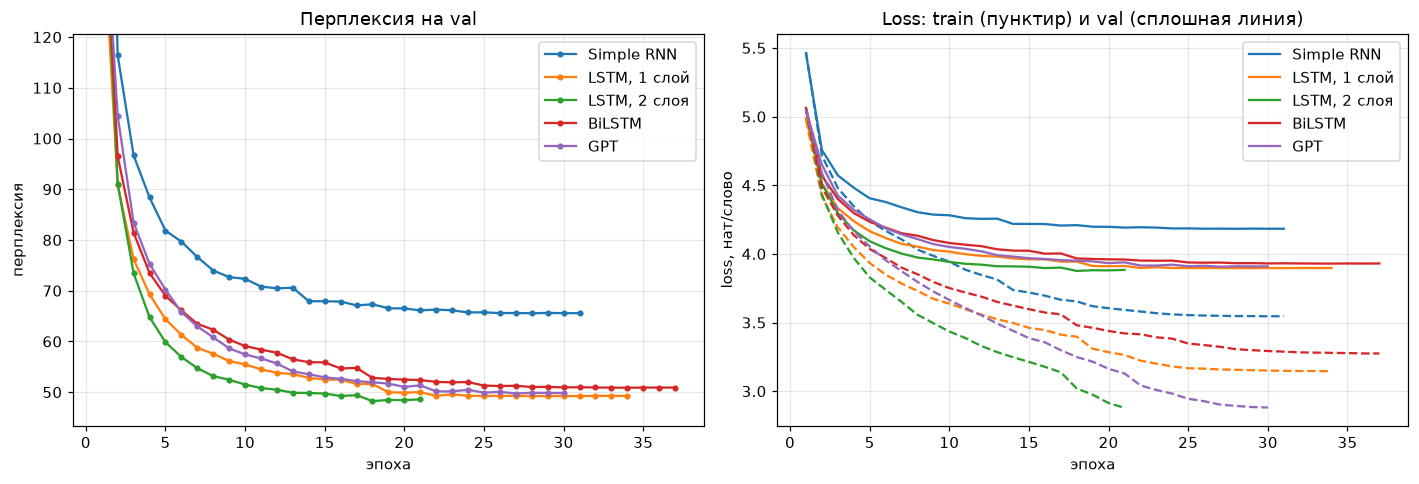

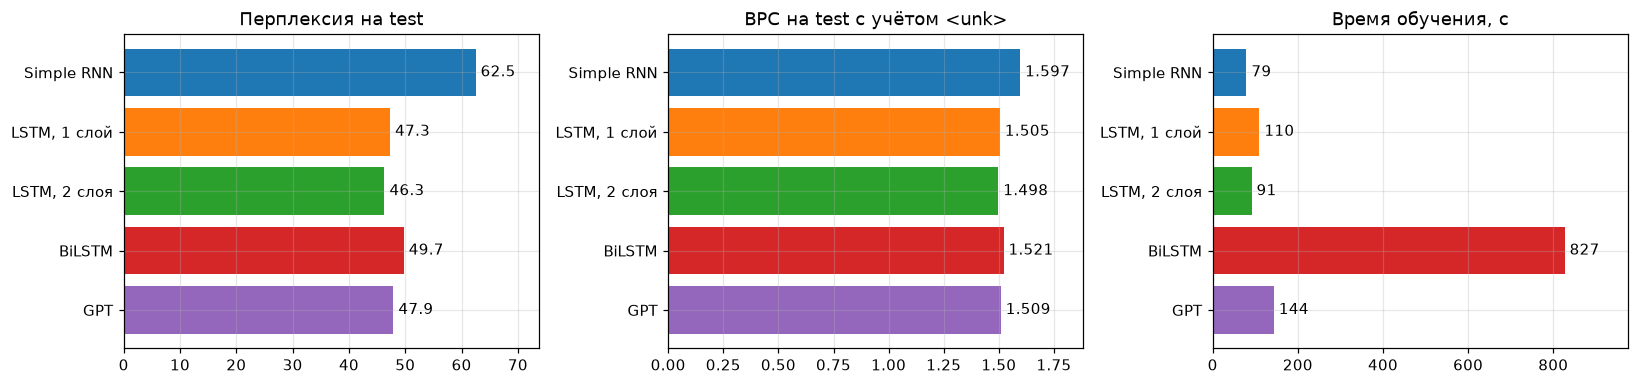

In [14]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
for i, (key, (_, history, _)) in enumerate(trained.items()):
    epochs = [h["epoch"] for h in history]
    name, color = CONFIGS[key]["name"], f"C{i}"
    axes[0].plot(epochs, [math.exp(h["val_loss"]) for h in history], "o-", ms=3, color=color, label=name)
    axes[1].plot(epochs, [h["val_loss"] for h in history], color=color, label=name)
    axes[1].plot(epochs, [h["train_loss"] for h in history], "--", color=color)
best_ppl = results["Val PPL"].min()
axes[0].set(xlabel="эпоха", ylabel="перплексия", title="Перплексия на val", ylim=(0.9 * best_ppl, 2.5 * best_ppl))
axes[1].set(xlabel="эпоха", ylabel="loss, нат/слово", title="Loss: train (пунктир) и val (сплошная линия)")
for ax in axes:
    ax.legend()
plt.tight_layout()
plt.savefig(IMG_DIR / "curves.png", bbox_inches="tight")
plt.show()

fig, axes = plt.subplots(1, 3, figsize=(15, 3.6))
colors = [f"C{i}" for i in range(len(results))]
titles = {"Test PPL": ("Перплексия на test", "{:.1f}"),
          "Test BPC с <unk>": ("BPC на test с учётом <unk>", "{:.3f}"),
          "Время обучения, с": ("Время обучения, с", "{:.0f}")}
for ax, (column, (title, fmt)) in zip(axes, titles.items()):
    ax.barh(results.index, results[column], color=colors)
    ax.invert_yaxis()
    ax.set_title(title)
    for j, value in enumerate(results[column]):
        ax.text(value, j, " " + fmt.format(value), va="center")
    ax.set_xlim(0, results[column].max() * 1.18)
plt.tight_layout()
plt.savefig(IMG_DIR / "test_metrics.png", bbox_inches="tight")
plt.show()

## 6. Генерация текста

Генерация авторегрессионная: модель получает затравку, выдаёт распределение следующего слова, мы выбираем
слово, дописываем его к контексту и повторяем. Выбор управляется **температурой** τ: логиты делятся на τ
перед softmax. При τ < 1 распределение острее — текст связнее, но однообразнее; при τ > 1 — площе:
разнообразнее, но бессвязнее; τ → 0 — **жадный** выбор самого вероятного слова. Токен `<unk>` при генерации
запрещён.

In [15]:
@torch.no_grad()
def generate_ids(model, prompt_ids, n_tokens=60, temperature=0.8, top_k=None, seed=0):
    """Продолжение затравки: на каждом шаге — следующее слово по последним SEQ_LEN словам."""
    model.eval()
    g = torch.Generator(device=device).manual_seed(seed)
    out = list(prompt_ids)
    for _ in range(n_tokens):
        logits = model.next_logits(torch.tensor([out[-SEQ_LEN:]], device=device))[0]
        logits[0] = float("-inf")                       # <unk> не генерируем
        if temperature == 0:                            # жадный выбор
            nxt = int(logits.argmax())
        else:
            logits = logits / temperature
            if top_k is not None:
                logits[logits < torch.topk(logits, top_k).values[-1]] = float("-inf")
            nxt = int(torch.multinomial(F.softmax(logits, dim=-1), 1, generator=g))
        out.append(nxt)
    return out[len(prompt_ids):]


def generate(model, prompt, **kwargs):
    prompt_ids = tok.encode(tok.tokenize(prompt))
    return tok.decode(prompt_ids + generate_ids(model, prompt_ids, **kwargs))


PROMPT = "“My dear Watson,” said Holmes,"
samples = {}
for key, (model, _, _) in trained.items():
    print(f"━━━ {CONFIGS[key]['name']} ━━━")
    for temperature in (0.5, 0.8, 1.0):
        samples[f"{key}, τ={temperature}"] = generate(model, PROMPT, n_tokens=60, temperature=temperature, seed=1)
        print(f"[τ = {temperature}] {samples[f'{key}, τ={temperature}']}\n")

━━━ Simple RNN ━━━
[τ = 0.5] “My dear Watson,” said Holmes, “I have been in the same time.”
“But that is the first thing,” said he, “I have a little to look at the door. I’ll see you,” said he. “There is a thousand in the power of the law.”
“I am

[τ = 0.8] “My dear Watson,” said Holmes, “I believe you have come. It is a problem which be made.”
“Did you your report to you now, a brave woman?”
“They are not, one will do.”
“There is a thousand in the power of this remarkable man, Watson, I will



[τ = 1.0] “My dear Watson,” said Holmes, shutting with a paper in manner. “The same problem has handled and I accept the shark. You cannot see a perfectly now.”
“Yes, Jack,” I suggested, one we left taking the girl? There were only long as the power of them in the original records, which will

━━━ LSTM, 1 слой ━━━
[τ = 0.5] “My dear Watson,” said Holmes, “I have been in the house for a few minutes, and I should have had a few hours of the morning.”
“You will find it.”
“Yes, I will do.”
“Well, well, I don’t think that I have taken a little nearer to

[τ = 0.8] “My dear Watson,” said Holmes, “I will make the truth. It is a problem which are made up my own heart. You cannot see a perfectly close case, but I think that there is no very necessary point to lose it.”
“There is a long way,” said Holmes.
“Yes, I will

[τ = 1.0] “My dear Watson,” said Holmes, shutting the matter, “you have attached to the problem which are made.”
“Did it your murder a man now enough a consideration of his highly

[τ = 0.5] “My dear Watson,” said Holmes, “I have been in my house for a time, and I have not heard of him.”
“I have a case,” said Holmes, “and I am not aware that it is more than I can be.”
“You have not heard of the first man’s wife,

[τ = 0.8] “My dear Watson,” said Holmes, “I have been in my house for a few minutes, and and I have had some days to your conclusion. I now tell a little startling of my evidence which would give me a wire for it.”
“There is no meaning in the matter, Mr. Holmes,” said I,



[τ = 1.0] “My dear Watson,” said Holmes, shutting the matter, “you have attached yourself from the discoloured and logical story of the struggle. You should see a perfectly American throbbing a little from his hand.”
“There is one positive point about the girl?” I asked.
“What sort can it be? Once, I will

━━━ BiLSTM ━━━
[τ = 0.5] “My dear Watson,” said Holmes, “I have been in the house for the last train.”
“I have no doubt that your Grace’s name was in a case of his own.”
“Yes, I will do you.”
“I am glad to tell you that you have the kindness to get down on

[τ = 0.8] “My dear Watson,” said Holmes, “I will make the truth. It is a problem which are made to accept the proceedings of the problem which I have now.”
“You have not not aware of me, Mr. Holmes?” said the inspector.
“I am very much indebted to you, Watson,” said



[τ = 1.0] “My dear Watson,” said Holmes, shutting the matter, “you have attached yourself in the criminal.”
Holmes had laid himself while he closed a thick wood, a huge and malignant, red-looking man with a one of self-contained girl? There was a long way of power upon her face and his pale voice, and

━━━ GPT ━━━
[τ = 0.5] “My dear Watson,” said Holmes, “I have been in the house for some years, and I have no doubt that you are here at present.”
“I have not heard of it yet,” said Holmes, “but I have been too much to blame.”
“You can only be surprised,” said Holmes



[τ = 0.8] “My dear Watson,” said Holmes, “I have been in the house for some years, and I have seldom heard of him.”
“I have now enough to do so,” said Holmes. “There is one little point which I have now left to blame. I hope that it is a statesman, and that I will

[τ = 1.0] “My dear Watson,” said Holmes, shutting his revolver, “you have attached yourself away in a distant jungle.”
“Did you your stepfather see his American master a brave gentleman?”
“Yes: Yes, one positive left.”
“Curious, Watson. I remember how it is. They all agreed that I know



**Жадная генерация** (τ → 0): всегда берём самое вероятное слово.

In [16]:
PROMPT_GREEDY = "It was late in the evening when"
for key, (model, _, _) in trained.items():
    samples[f"{key}, greedy"] = generate(model, PROMPT_GREEDY, n_tokens=40, temperature=0)
    print(f"━━━ {CONFIGS[key]['name']} ━━━\n{samples[f'{key}, greedy']}\n")

━━━ Simple RNN ━━━
It was late in the evening when I had been seen by the police, and I had no doubt that I had seen him.
“‘I am sorry to see you,” said Holmes, “I am sure that you are

━━━ LSTM, 1 слой ━━━
It was late in the evening when I had been in the house. I had a note of the police, and I had a note to my friend, and I had a note to my friend, and I had a note to my



━━━ LSTM, 2 слоя ━━━
It was late in the evening when I heard the sound of the latch.
“I have no doubt that you have been in the house,” said he. “I have no doubt that you are a very busy man, and

━━━ BiLSTM ━━━
It was late in the evening when I had been able to see the door.
“I have been a very busy man,” said he. “I have no doubt that you have been in the habit of seeing you.”

━━━ GPT ━━━
It was late in the evening when I heard the sound of a sharp tap at the door.
“I am sorry to hear you know, Mr. Holmes,” said Holmes, “but I have no doubt that you have been



Длинный фрагмент от лучшей по перплексии модели (τ = 0.8):

In [17]:
best_key = min(trained, key=lambda k: results.loc[CONFIGS[k]["name"], "Test PPL"])
samples[f"{best_key}, long"] = generate(trained[best_key][0], "I had called upon my friend Sherlock Holmes",
                                        n_tokens=250, temperature=0.8, seed=7)
print(f"{CONFIGS[best_key]['name']}:\n\n{samples[f'{best_key}, long']}")
pd.Series(samples).to_json(RESULTS_DIR / "samples.json", force_ascii=False, indent=1)

LSTM, 2 слоя:

I had called upon my friend Sherlock Holmes, with the surprise which I had given myself to the previous morning.
“It was a man who knew that I was an excellent man, for I was never denying that I could not serve the place which none could be known. She had asked me to meet the horses, but I ended by the same instant and left the room, with no one upon her own night. The idea was that he was most mistaken.”
“You have an excellent cigar, or what I have heard, is the most exact thing of your life and wife?”
“I have always my share of the case, Watson,” said McMurdo, glancing out at the ceiling, “but you have no only courage for the reason which we have recollection. And this is the truth.”
“Not for the first link.”
“But the security?”
“It was my first question for a warrant. You have hopes of Beecher’s honour, Watson, and that I may be delighted to take those fresh facts which would indicate my case.”
I looked at him from the dark-chair attitude, which showed me that I woul

### Что выучило внимание GPT

Карты самовнимания для одной фразы: строка — слово, которое «смотрит», столбец — на какое слово, цвет — вес
внимания (усреднён по 4 головам слоя). Выше диагонали пусто: это маска, будущее не видно.

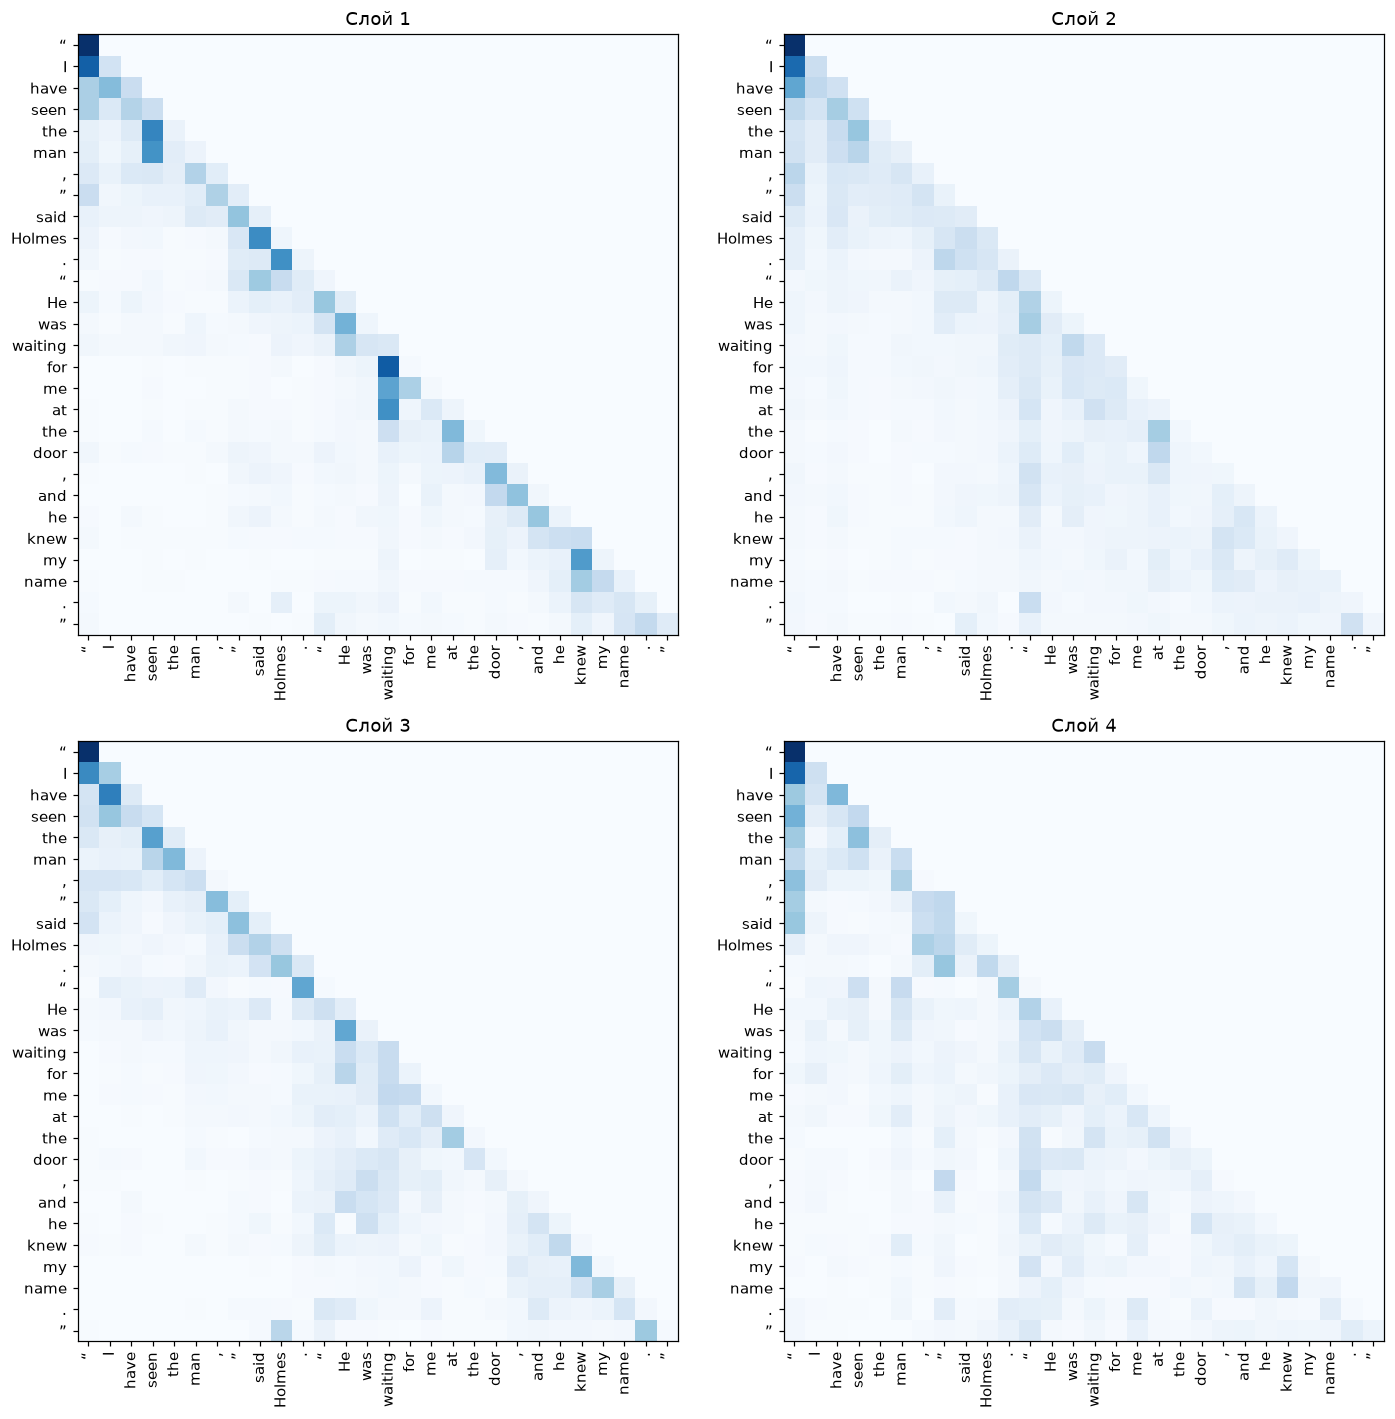

In [18]:
gpt = trained["gpt"][0].eval()
phrase = "“I have seen the man,” said Holmes. “He was waiting for me at the door, and he knew my name.”"
phrase_ids = tok.encode(tok.tokenize(phrase))
with torch.no_grad():
    gpt.next_logits(torch.tensor([phrase_ids], device=device))
words = [tok.itos[i] for i in phrase_ids]
fig, axes = plt.subplots(2, 2, figsize=(13, 13))
for layer, (ax, block) in enumerate(zip(axes.flat, gpt.blocks)):
    ax.imshow(block.attn.last_attention[0].mean(0).cpu(), cmap="Blues")
    ax.set_xticks(range(len(words)), words, rotation=90)
    ax.set_yticks(range(len(words)), words)
    ax.set_title(f"Слой {layer + 1}")
    ax.grid(False)
plt.tight_layout()
plt.savefig(IMG_DIR / "attention.png", bbox_inches="tight")
plt.show()

Головы разных слоёв занимаются разным. В 1-м и 3-м слоях внимание в основном локальное — на предыдущее слово
(яркая полоса сразу под диагональю): этого хватает для статистики соседних слов. Во 2-м и 4-м слоях появляются
вертикальные полосы под открывающими кавычками `“`: слова внутри реплики смотрят на начало своей реплики.
Модели нужно помнить, что она «внутри прямой речи», чтобы вовремя закрыть кавычку, — рекуррентной сети для этого
приходится держать признак в скрытом состоянии, а трансформер просто «оглядывается» на нужную позицию.

### Насколько сгенерированный текст «свой»

Возьмём начала 40 случайных абзацев теста (по 10 токенов), продолжим каждое на 50 токенов (τ = 0.8)
и сравним с тем, как продолжил сам Конан Дойл:
- **4-граммы из train, %** — доля четвёрок подряд идущих токенов, которые встречаются в обучающем тексте.
  Слишком много — модель цитирует заученное, слишком мало — не держит устойчивых оборотов;
- **distinct-2, %** — доля уникальных биграмм среди всех: мера разнообразия;
- **повторы, %** — доля 4-грамм, которые повторяются внутри одного продолжения: мера зацикливания.

In [19]:
train_4grams = set(zip(*(tokens["train"][i:] for i in range(4))))
test_paragraphs = [tok.tokenize(p) for p in texts["test"].split("\n") if len(p.split()) >= 70]
picked = random.Random(0).sample(test_paragraphs, 40)
PROMPT_LEN, GEN_LEN = 10, 50


def text_stats(continuations):
    grams4 = [list(zip(*(c[i:] for i in range(4)))) for c in continuations]
    grams2 = [g for c in continuations for g in zip(c, c[1:])]
    return {"4-граммы из train, %": 100 * np.mean([g in train_4grams for gs in grams4 for g in gs]),
            "distinct-2, %": 100 * len(set(grams2)) / len(grams2),
            "повторы, %": 100 * np.mean([1 - len(set(gs)) / len(gs) for gs in grams4])}


rows = [{"Модель": "Конан Дойл (оригинал)", **text_stats([p[PROMPT_LEN:PROMPT_LEN + GEN_LEN] for p in picked])}]
for key, (model, _, _) in trained.items():
    continuations = [[tok.itos[i] for i in generate_ids(model, tok.encode(p[:PROMPT_LEN]), n_tokens=GEN_LEN,
                                                        temperature=0.8, seed=j)]
                     for j, p in enumerate(picked)]
    rows.append({"Модель": CONFIGS[key]["name"], **text_stats(continuations)})
generation_stats = pd.DataFrame(rows).set_index("Модель")
generation_stats.to_csv(RESULTS_DIR / "generation_stats.csv")
display(generation_stats.round(1))

,"4-граммы из train, %","distinct-2, %","повторы, %"
Модель,,,
Конан Дойл (оригинал),16.8,83.5,0.1
Simple RNN,39.2,64.9,0.7
"LSTM, 1 слой",38.6,66.3,0.9
"LSTM, 2 слоя",33.6,69.7,0.5
BiLSTM,35.6,68.8,0.6
GPT,42.6,68.2,0.6


## 7. Почему BiLSTM нельзя учить как обычную языковую модель

Проверим на практике. Возьмём двунаправленную LSTM того же размера и будем учить её так же, как
однонаправленные модели: на каждой позиции *t* предсказывать слово *t+1*. Обратный проход на позиции *t*
уже прочитал слово *t+1*, то есть правильный ответ попадает сети на вход:

```
вход:  The   dog     barked   loudly
цель:  dog   barked  loudly   .
       ↑ обратный проход на позиции «The» уже прочитал «loudly», «barked» и «dog»
```

Обучим такую модель 3 эпохи и сравним loss в режиме обучения (будущее видно) и в честном режиме, когда
следующего слова ещё нет, как при генерации.

In [20]:
@torch.no_grad()
def teacher_forced_loss(model, data, windows_per_batch=256):
    """Loss «как при обучении»: окна по SEQ_LEN слов, предсказание на каждой позиции окна."""
    model.eval()
    starts = torch.arange(0, len(data) - SEQ_LEN - 1, SEQ_LEN, device=data.device)
    total, n = 0.0, 0
    for i in range(0, len(starts), windows_per_batch):
        chunk = data[starts[i:i + windows_per_batch, None] + torch.arange(SEQ_LEN + 1, device=data.device)]
        logits = model(chunk[:, :-1])
        total += F.cross_entropy(logits.reshape(-1, V), chunk[:, 1:].reshape(-1), reduction="sum").item()
        n += chunk[:, 1:].numel()
    return total / n


torch.manual_seed(SEED)
naive_bilstm = RNNLM(V, "lstm", hidden=256, layers=1, dropout=0.4, bidirectional=True).to(device)
train_model(naive_bilstm, lr=2e-3, max_epochs=3, patience=3)

leak = []
for name, model in [("LSTM, 1 слой", trained["lstm1"][0]), ("«наивная» BiLSTM", naive_bilstm)]:
    tf_loss, honest_loss = teacher_forced_loss(model, ids["val"]), evaluate(model, ids["val"])
    leak.append({"Модель": name, "loss как при обучении": tf_loss, "PPL как при обучении": math.exp(tf_loss),
                 "честный loss": honest_loss, "честная PPL": math.exp(honest_loss)})
display(pd.DataFrame(leak).set_index("Модель").round(2))
print("Генерация «наивной» BiLSTM (τ = 0.8):\n", generate(naive_bilstm, PROMPT, n_tokens=40, temperature=0.8, seed=1))
print("\nЖадная генерация:\n", generate(naive_bilstm, PROMPT_GREEDY, n_tokens=30, temperature=0))

эпоха  1 | lr 2.0e-03 | train loss 7.263 | val loss 7.266 | val PPL 1431.4 |    3 с


эпоха  2 | lr 2.0e-03 | train loss 5.392 | val loss 5.438 | val PPL  230.0 |    6 с


эпоха  3 | lr 2.0e-03 | train loss 5.220 | val loss 5.257 | val PPL  191.8 |    9 с


,loss как при обучении,PPL как при обучении,честный loss,честная PPL
Модель,,,,
"LSTM, 1 слой",3.94,51.38,3.90,49.22
«наивная» BiLSTM,0.11,1.12,5.26,191.83


Генерация «наивной» BiLSTM (τ = 0.8):
 “My dear Watson,” said Holmes,, with the body in upon a dark were in in discoloured. and I have had than to to your minutes to his pocket. It had kept to to.”
“‘, one it it

Жадная генерация:
 It was late in the evening when.
“No, and the window, and the window.
“No, and the window, and the window.
“No, and


## 8. Выводы

1. **Simple RNN — худшая модель** (перплексия на тесте 62,5 против 46–50 у остальных). Градиент в простой
   рекуррентной сети затухает за несколько шагов, и из 64 слов контекста она реально использует лишь последние.
2. **LSTM решает эту проблему**: вентили и аддитивное обновление ячейки памяти снижают перплексию на четверть
   (62,5 → 47,3). Второй слой даёт ещё немного (46,3 — лучший результат), но только вместе с подобранной регуляризацией.
3. **GPT на уровне LSTM, но не лучше** (47,9). На корпусе в 0,7 млн токенов трансформеру не хватает данных,
   чтобы реализовать своё преимущество — прямой доступ ко всему контексту без затухания. Он сильнее всех запоминает
   обучающий текст: перплексия на train ≈ 18 против ≈ 50 на val, и больше всех копирует из train готовые обороты.
   Карты внимания показывают, что головы выучили осмысленные функции: соседние слова и границы прямой речи.
4. **BiLSTM работает только в постановке many-to-one** и всё равно уступает однонаправленной LSTM (49,7 против 47,3),
   а учится в 7,5 раза дольше: на каждое целевое слово нужен отдельный проход по окну. Обратный проход по прошлому
   контексту почти ничего не добавляет — самые важные для предсказания последние слова окна он читает первыми.
   Двунаправленность нужна, когда последовательность известна целиком (классификация, разметка, BERT),
   а не для генерации. «Наивная» BiLSTM показывает перплексию 1,1 при обучении, потому что видит ответ,
   а при честной проверке — 192, и генерирует мусор.
5. **Регуляризация важнее архитектуры.** Подбор dropout и learning rate менял перплексию LSTM на 6–8 %, а вся
   разница между однослойной LSTM, двухслойной LSTM и GPT — 3,5 %. Оптимальный dropout у LSTM высокий: 0,45–0,6.
6. **Генерация.** Все модели пишут правдоподобный по грамматике текст в стиле Конан Дойла: диалоги в кавычках,
   «said Holmes», обращения «Watson», «Mr. Holmes». Но смысл держится не дольше одного-двух предложений.
   При τ = 0.5 текст гладкий, но шаблонный, при τ = 1.0 — разнообразный, но с ошибками согласования, а жадная
   генерация зацикливается. Модели заимствуют из train в 2–2,5 раза больше 4-грамм, чем сам автор
   (34–43 % против 17 %), и менее разнообразны (distinct-2 65–70 % против 83 %).
7. **Пословная токенизация** даёт короткие последовательности (4,4 символа на токен) и генерацию только из настоящих
   слов, но платит словарём: 9,7 тыс. токенов, 2,5 млн параметров на эмбеддинги и 3,2 % `<unk>` в тесте.
   Лучшая модель тратит 1,27 бита на символ без учёта `<unk>` и 1,50 — с поправкой на написание неизвестных слов
   (+0,23 бита на символ). Именно второе число честно сравнивать с посимвольными и BPE-моделями команды.